In [7]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 


In [9]:
df=pd.read_csv("diabetes.csv")
print(df.shape)
df.head()

(768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [10]:
print(df["Outcome"].value_counts())

Outcome
0    500
1    268
Name: count, dtype: int64


In [11]:
df.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


In [14]:
cols=["Glucose","BloodPressure","SkinThickness","Insulin","BMI"]
print((df[cols]==0).sum())

Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64


In [15]:
df[cols] = df[cols].replace(0, np.nan)
print(df.isna().sum())

Pregnancies                   0
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                       0
dtype: int64


In [16]:
from sklearn.model_selection import train_test_split
train_df,test_df=train_test_split(
    df,test_size=0.2,random_state=42,stratify=df["Outcome"]
)
print(train_df.shape,test_df.shape)

(614, 9) (154, 9)


In [17]:
medians=train_df[cols].median()
print(medians)
train_df=train_df.fillna(medians)
test_df=test_df.fillna(medians)
print(train_df.isna().sum().sum(),test_df.isna().sum().sum())

Glucose          117.0
BloodPressure     72.0
SkinThickness     29.0
Insulin          125.0
BMI               32.4
dtype: float64
0 0


In [22]:
X_train=train_df.drop("Outcome",axis=1).values
y_train=train_df["Outcome"].values
X_test=test_df.drop("Outcome",axis=1).values
y_test=test_df["Outcome"].values
print(X_train.shape, y_train.shape)
print(X_test.shape, y_test.shape)

(614, 8) (614,)
(154, 8) (154,)


In [23]:
mu = X_train.mean(axis=0)
sigma = X_train.std(axis=0)

X_train = (X_train - mu) / sigma
X_test = (X_test - mu) / sigma


In [24]:
print(X_train.mean(axis=0).round(2))
print(X_train.std(axis=0).round(2))
print(np.bincount(y_train), np.bincount(y_test))


[-0. -0.  0. -0. -0.  0. -0. -0.]
[1. 1. 1. 1. 1. 1. 1. 1.]
[400 214] [100  54]


In [25]:
def sigmoid(z):
    return 1/(1+np.exp(-z))

In [26]:
print(sigmoid(0))
print(sigmoid(5))
print(sigmoid(-5))
print(sigmoid(np.array([-2, 0, 2])))

0.5
0.9933071490757153
0.0066928509242848554
[0.11920292 0.5        0.88079708]


In [27]:
def compute_cost(X,y,w,b,lam=0):
    m=X.shape[0]
    f=sigmoid(X@w+b)
    eps=1e-15
    loss=-(y*np.log(f+eps)+(1-y)*np.log(1-f+eps))
    return loss.mean()+(lam/(2*m))*np.sum(w**2)




In [29]:
def compute_gradient(X,y,w,b,lam=0):
    m=X.shape[0]
    f=sigmoid(X@w+b)
    err=f-y
    dw=(X.T@err)/m+(lam/m)*w
    db=err.mean()
    return dw,db

In [30]:
w_test = np.zeros(X_train.shape[1])
dw, db = compute_gradient(X_train, y_train, w_test, 0.0)
print(dw.shape)
print(dw.round(3))
print(round(db, 3))

(8,)
[-0.099 -0.244 -0.087 -0.112 -0.117 -0.157 -0.079 -0.115]
0.151


In [31]:
def gradient_descent(X,y,alpha=0.1,iters=1000,lam=0):
    w=np.zeros(X.shape[1])
    b=0.0
    history=[]
    for i in range(iters):
        dw,db=compute_gradient(X,y,w,b,lam)
        w-=alpha*dw
        b-=alpha*db
        history.append(compute_cost(X,y,w,b,lam))
    return w,b,history

In [32]:
w, b, history = gradient_descent(X_train, y_train, alpha=0.1, iters=1000, lam=0)
print(history[0], history[-1])
print(w.round(2), round(b, 2))

0.6765754202592378 0.45307692673668903
[ 0.38  1.21 -0.05  0.02 -0.08  0.7   0.24  0.15] -0.88


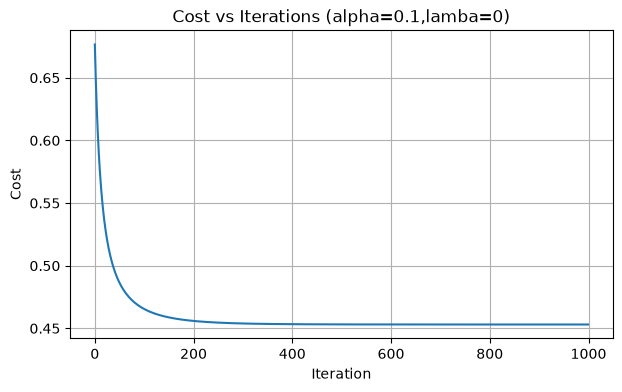

In [33]:
plt.figure(figsize=(7,4))
plt.plot(history)
plt.xlabel("Iteration")
plt.ylabel("Cost")
plt.title("Cost vs Iterations (alpha=0.1,lamba=0)")
plt.grid(True)
plt.savefig("cost-curve.png", dpi=150, bbox_inches="tight")
plt.show()

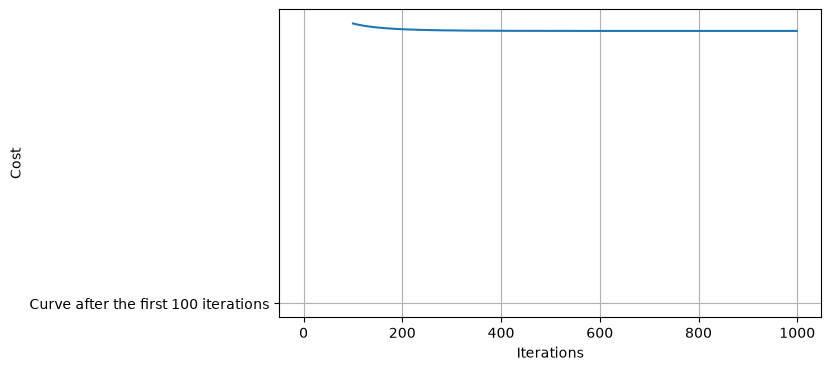

In [37]:
plt.figure(figsize=(7,4))
plt.plot(range(100,1000),history[100:])
plt.xlabel("Iterations")
plt.ylabel("Cost")
plt.plot("Curve after the first 100 iterations")
plt.grid(True)
plt.show()

In [38]:
def predict(X,w,b,threshold=0.5):
    probs=sigmoid(X@w+b)
    return (probs>=threshold).astype(int)

In [39]:
y_pred_train=predict(X_train,w,b)
y_pred_test=predict(X_test,w,b)
train_acc=(y_pred_train==y_train).mean()
test_acc=(y_pred_test==y_test).mean()
print("Train accuracy:",round(train_acc,3))
print("Test accuracy",round(test_acc,3))

Train accuracy: 0.796
Test accuracy 0.708


In [40]:
baseline_acc=(y_test==0).mean()
print("Always-say-0 accuracy:",round(baseline_acc,3))

Always-say-0 accuracy: 0.649


In [42]:
tp=((y_pred_test==1)&(y_test==1)).sum()
tn=((y_pred_test==0) &(y_test==0)).sum()
fp=((y_pred_test==1) &(y_pred_test==0)).sum()
fn=((y_pred_test==0) &(y_pred_test==1)).sum()
print("Caught diabetic (TP):   ", tp)
print("Correct healthy (TN):   ", tn)
print("False alarm (FP):       ", fp)
print("Missed diabetic (FN):   ", fn)

Caught diabetic (TP):    27
Correct healthy (TN):    82
False alarm (FP):        0
Missed diabetic (FN):    0


In [44]:
print(tp+tn+fp+fn)
print(tp+fn,tn+tp)
print("Accuracy:",round((tp+tn)/(tp+tn+fp+fn),3))

109
27 109
Accuracy: 1.0


In [45]:
recall=tp/(tp+fn)
precision=tp/(tp+fp)
print("Recall:",round(recall,3))
print("Precision:",round(precision,3))

Recall: 1.0
Precision: 1.0


In [47]:
w1, b1, hist1 = gradient_descent(X_train, y_train, alpha=0.001, iters=1000, lam=0)
print("first cost:", round(hist1[0], 3), " last cost:", round(hist1[-1], 3))


first cost: 0.693  last cost: 0.585


KeyboardInterrupt: 

Exception ignored in: 'zmq.backend.cython._zmq.Frame.__dealloc__'
Traceback (most recent call last):
  File "zmq/backend/cython/_zmq.py", line 179, in zmq.backend.cython._zmq._check_rc
    PyErr_CheckSignals()
KeyboardInterrupt: 


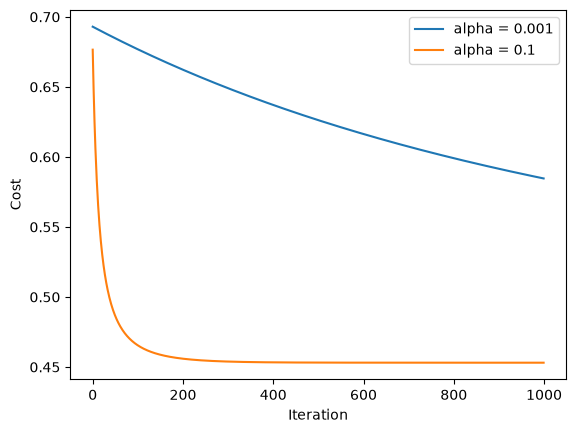

In [51]:
plt.plot(hist1, label="alpha = 0.001")
w2, b2, hist2 = gradient_descent(X_train, y_train, alpha=0.1, iters=1000, lam=0)
plt.plot(hist2, label="alpha = 0.1")
plt.xlabel("Iteration"); plt.ylabel("Cost"); plt.legend()
plt.show()

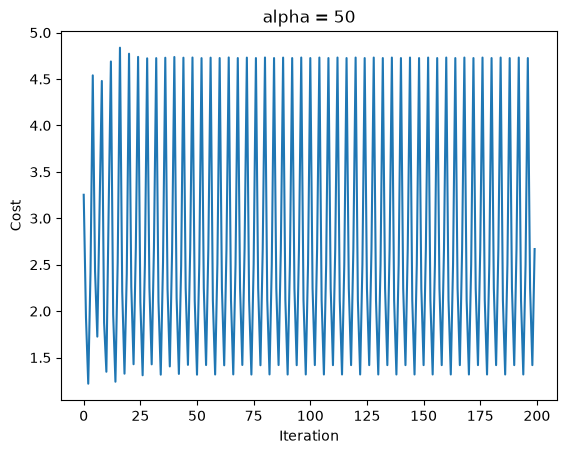

In [53]:
w_big, b_big, hist_big = gradient_descent(X_train, y_train, alpha=50, iters=200, lam=0)
plt.plot(hist_big)
plt.title("alpha = 50")
plt.xlabel("Iteration"); plt.ylabel("Cost")
plt.savefig("lr-divergence.png", dpi=150, bbox_inches="tight")
plt.show()


In [55]:
w_a,b_a,_=gradient_descent(X_train,y_train,alpha=0.1,iters=1000,lam=0)
w_b,b_b,_=gradient_descent(X_train,y_train,alpha=0.1,iters=1000,lam=100)
print("lambda = 0  :", w_a.round(2))
print("lambda = 100:", w_b.round(2))

lambda = 0  : [ 0.38  1.21 -0.05  0.02 -0.08  0.7   0.24  0.15]
lambda = 100: [0.17 0.53 0.07 0.12 0.11 0.3  0.13 0.15]


In [58]:
lams=[0,0.1,1,10,100]
for lam in lams:
    w_l,b_l,_=gradient_descent(X_train,y_train,alpha=0.1,iters=1000,lam=lam)
    print("lambda =", lam, "  sum of |weights| =", np.abs(w_l).sum().round(3))


lambda = 0   sum of |weights| = 2.825
lambda = 0.1   sum of |weights| = 2.819
lambda = 1   sum of |weights| = 2.765
lambda = 10   sum of |weights| = 2.363
lambda = 100   sum of |weights| = 1.573


In [71]:
lams = [0, 0.1, 1, 10, 100]

for lam in lams:
    w_l, b_l, _ = gradient_descent(X_train, y_train, alpha=0.1, iters=1000, lam=lam)
    acc_l = (predict(X_test, w_l, b_l) == y_test).mean()
    print("lambda =", lam, "  sum|w| =", np.abs(w_l).sum().round(3), "  test acc =", acc_l.round(3))

lambda = 0   sum|w| = 2.825   test acc = 0.708
lambda = 0.1   sum|w| = 2.819   test acc = 0.708
lambda = 1   sum|w| = 2.765   test acc = 0.701
lambda = 10   sum|w| = 2.363   test acc = 0.688
lambda = 100   sum|w| = 1.573   test acc = 0.74


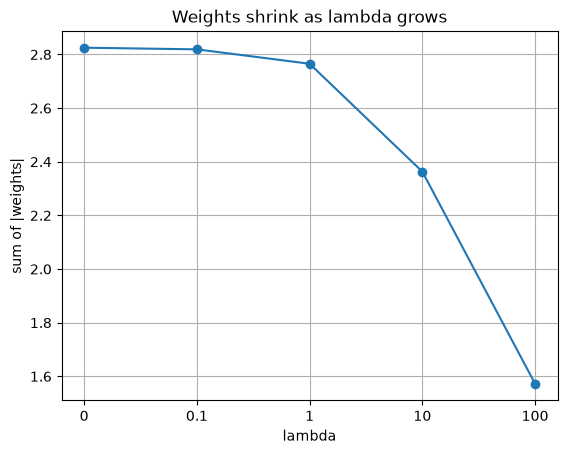

In [73]:
lams = [0, 0.1, 1, 10, 100]
sums = []

for lam in lams:
    w_l, b_l, _ = gradient_descent(X_train, y_train, alpha=0.1, iters=1000, lam=lam)
    sums.append(np.abs(w_l).sum())

plt.plot(range(len(lams)), sums, marker="o")
plt.xticks(range(len(lams)), lams)
plt.xlabel("lambda"); plt.ylabel("sum of |weights|")
plt.title("Weights shrink as lambda grows")
plt.grid(True)
plt.savefig("lambda-weights.png", dpi=150, bbox_inches="tight")
plt.show()

In [67]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score
models = {
    "sklearn LogisticRegression": LogisticRegression(),
    "Random Forest": RandomForestClassifier(random_state=42),
    "SVC": SVC(),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
}
for name, model in models.items():
        model.fit(X_train, y_train)
        pred = model.predict(X_test)
        print(f"{name:<28} acc={accuracy_score(y_test, pred):.3f}  "
          f"precision={precision_score(y_test, pred):.3f}  "
          f"recall={recall_score(y_test, pred):.3f}")


sklearn LogisticRegression   acc=0.708  precision=0.600  recall=0.500
Random Forest                acc=0.773  precision=0.702  recall=0.611
SVC                          acc=0.740  precision=0.652  recall=0.556
Gradient Boosting            acc=0.753  precision=0.682  recall=0.556


In [68]:
w0, b0, _ = gradient_descent(X_train, y_train, alpha=0.1, iters=1000, lam=0)
p = predict(X_test, w0, b0)
print(f"{'Mine (lambda=0)':<28} acc={accuracy_score(y_test, p):.3f}  "
      f"precision={precision_score(y_test, p):.3f}  "
      f"recall={recall_score(y_test, p):.3f}")

Mine (lambda=0)              acc=0.708  precision=0.600  recall=0.500


In [69]:
for t in [0.5, 0.4, 0.3]:
    p_t = predict(X_test, w0, b0, threshold=t)
    print(t, "precision:", round(precision_score(y_test, p_t), 3),
             "recall:", round(recall_score(y_test, p_t), 3))

0.5 precision: 0.6 recall: 0.5
0.4 precision: 0.614 recall: 0.648
0.3 precision: 0.597 recall: 0.796
